# Customer Segmentation: RFM Rules vs K-Means (Exploratory Analysis)

> **Synthetic data.** Every record in this project is simulated. The dataset was generated to resemble a direct-to-consumer
> beauty and wellness CRM export. No real company, customer or campaign is involved, and nothing here describes real business results.

**Purpose.** Group 1,000 customers into segments a marketing team could act on, and test honestly whether the data
contains natural customer clusters or only gradients that are better described by simple, transparent rules.

**Outline**
1. Setup
2. Data quality and cleaning
3. Customer behaviour (recency, orders, spend, AOV, tenure)
4. Is the churn score independent information?
5. Deterministic RFM scores and why the original segments were unstable
6. Primary segmentation: recency band x value tier
7. Clustering: does K-Means find real structure?
8. Revalidating customer insights (channels, categories, engagement)
9. Reconciliation of the original project's figures
10. Exports
11. Limitations

This notebook is the canonical workflow. Every number in the README and reports is produced here.

In [1]:
import json, sys, warnings
from pathlib import Path
warnings.filterwarnings("ignore")

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn, scipy
from scipy import stats
from sklearn.metrics import adjusted_rand_score

from src.config import (CHART_DIR, CLEAN_PATH, PROCESSED_DIR, REPORT_TABLE_DIR, RANDOM_STATE,
                        HIGH_CHURN_THRESHOLD, ANALYSIS_DATE)
from src import data_cleaning as dc, segmentation as sg, clustering as cl, stats_tests as st

for d in (CHART_DIR, PROCESSED_DIR, REPORT_TABLE_DIR, CLEAN_PATH.parent):
    d.mkdir(parents=True, exist_ok=True)

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 150, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.titleweight": "bold"})
METRICS = {}

def save(fig, name):
    fig.savefig(CHART_DIR / name, bbox_inches="tight")
    plt.show()

print("python", sys.version.split()[0], "| pandas", pd.__version__, "| numpy", np.__version__,
      "| scikit-learn", sklearn.__version__, "| scipy", scipy.__version__, "| matplotlib", matplotlib.__version__)

python 3.9.12 | pandas 1.4.2 | numpy 1.21.5 | scikit-learn 1.0.2 | scipy 1.7.3 | matplotlib 3.5.1


## 2. Data quality and cleaning

In [2]:
raw = dc.load_raw()
quality = dc.quality_report(raw)
pd.Series(quality)

rows                                  1010
columns                                 13
exact_duplicate_rows                    10
duplicate_customer_ids                  10
missing_gender                         180
missing_age                             48
missing_frequency                       26
zero_frequency_with_spend               17
age_under_18                            75
signup_after_last_purchase               0
recency_reference_dates       [2025-05-01]
monetary_max                        3059.6
monetary_skew                         4.88
dtype: object

Key facts from the raw file:
- Recency is measured against a single reference date (2025-05-01) for every row, so recency and tenure are consistent.
- All duplicated `customer_id`s are exact duplicate rows, so dropping them loses nothing.
- Some customers have **zero orders but positive spend and a purchase date**. That is impossible, so these are corrected to 1 order and flagged.
- Some customers are **under 18**. They are kept but flagged, because marketing to minors needs consent checks.
- Spend is heavily right-skewed. The original project capped it at the 99th percentile; here every revenue figure uses **uncapped** spend, and clustering uses `log1p(spend)` instead.

In [3]:
df, cleaning_log = dc.clean(raw)
METRICS["data_quality"] = quality
METRICS["customers"] = len(df)
cleaning_log

,step,rows_affected,detail
0,Drop exact duplicate rows,10,Every duplicated customer_id was an exact copy
1,Standardise gender,180,M/F mapped to Male/Female; missing kept as 'Un...
2,Standardise category case,0,Title case
3,"Parse dates, derive tenure_days",0,Reference date 2025-05-01
4,Correct impossible frequency,17,frequency 0 with spend > 0 set to 1 (minimum c...
5,Impute missing frequency,26,Median of observed values (4); flagged
6,Impute missing age,48,Median; flagged. Age is not used for segmentation
7,Flag customers under 18,75,Kept; flagged for marketing-consent review
8,Add log1p(monetary_value),0,Used for clustering instead of a 99th-percenti...
9,Derive average order value,43,AOV = spend / orders; left blank where frequen...


In [4]:
df["frequency_flag"].value_counts()

observed                    957
imputed_median               26
zero_with_spend_set_to_1     17
Name: frequency_flag, dtype: int64

## 3. Customer behaviour

In [5]:
aov_obs = df["aov"].dropna()
obs = df[df["frequency_flag"] == "observed"]
behaviour = {
    "customers": len(df),
    "total_revenue_uncapped": df["monetary_value"].sum(),
    "mean_spend_per_customer": df["monetary_value"].mean(),
    "median_spend_per_customer": df["monetary_value"].median(),
    "mean_orders_per_customer": df["frequency"].mean(),
    "median_orders_per_customer": df["frequency"].median(),
    "aov_customers_with_observed_orders": len(aov_obs),
    "aov_mean_of_customer_aov": aov_obs.mean(),
    "aov_median_of_customer_aov": aov_obs.median(),
    "aov_order_weighted": obs["monetary_value"].sum() / obs["frequency"].sum(),
    "median_recency_days": df["recency_days"].median(),
    "median_tenure_days": df["tenure_days"].median(),
    "min_tenure_days": int(df["tenure_days"].min()),
    "customers_tenure_le_180": int((df["tenure_days"] <= 180).sum()),
    "corr_orders_spend_spearman": stats.spearmanr(df["frequency"], df["monetary_value"]).correlation,
}
METRICS["behaviour"] = behaviour
pd.Series(behaviour).round(3)

customers                               1000.000
total_revenue_uncapped                260484.000
mean_spend_per_customer                  260.484
median_spend_per_customer                203.280
mean_orders_per_customer                   4.002
median_orders_per_customer                 4.000
aov_customers_with_observed_orders       957.000
aov_mean_of_customer_aov                  85.224
aov_median_of_customer_aov                54.805
aov_order_weighted                        64.496
median_recency_days                      202.000
median_tenure_days                       488.500
min_tenure_days                          121.000
customers_tenure_le_180                   87.000
corr_orders_spend_spearman                -0.022
dtype: float64

**Average order value.** The original executive summary reported "AOV $253", which is actually average *total spend per customer*.
AOV is spend divided by orders, and it is only computed here where the order count was observed (corrected or imputed counts are excluded).
Two valid definitions are shown: the mean of each customer's AOV, and the order-weighted AOV (total spend divided by total orders).
They differ because customers with few orders tend to have larger baskets.

**Tenure.** The newest customer signed up months before the analysis date, so the data contains **no recently acquired customers**.
Any segment called "New Customers" is not supportable.

**Orders and spend are almost unrelated** (rank correlation near zero). A customer's order count says little about how much they spend.

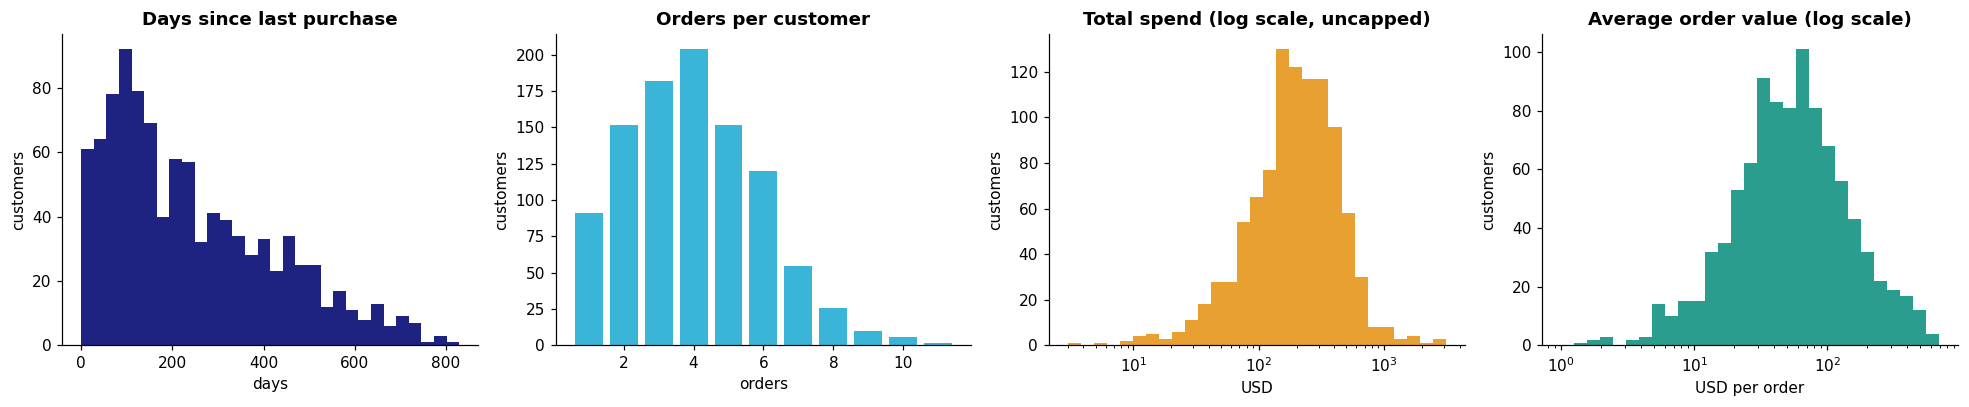

In [6]:
fig, ax = plt.subplots(1, 4, figsize=(18, 3.8))
ax[0].hist(df["recency_days"], bins=30, color="#1e2280"); ax[0].set_title("Days since last purchase"); ax[0].set_xlabel("days")
ax[1].bar(*np.unique(df["frequency"], return_counts=True), color="#3ab5d8"); ax[1].set_title("Orders per customer"); ax[1].set_xlabel("orders")
ax[2].hist(df["monetary_value"], bins=np.logspace(np.log10(3), np.log10(3100), 30), color="#e8a030"); ax[2].set_xscale("log")
ax[2].set_title("Total spend (log scale, uncapped)"); ax[2].set_xlabel("USD")
ax[3].hist(aov_obs, bins=np.logspace(np.log10(1), np.log10(aov_obs.max()), 30), color="#2a9d8f"); ax[3].set_xscale("log")
ax[3].set_title("Average order value (log scale)"); ax[3].set_xlabel("USD per order")
for a in ax: a.set_ylabel("customers")
fig.tight_layout(); save(fig, "01_customer_behaviour_distributions.png")

## 4. Is the churn score independent information?

In [7]:
rho = stats.spearmanr(df["recency_days"], df["churn_risk_score"]).correlation
from sklearn.isotonic import IsotonicRegression
iso = IsotonicRegression().fit(df["recency_days"], df["churn_risk_score"])
r2_iso = 1 - ((df["churn_risk_score"] - iso.predict(df["recency_days"]))**2).sum() / ((df["churn_risk_score"] - df["churn_risk_score"].mean())**2).sum()
over_365 = df[df["recency_days"] > 365]
binned = df.groupby(pd.cut(df["recency_days"], [-1, 90, 180, 365, 900]))["churn_risk_score"].agg(["count", "median", "min", "max"])
high_churn = (df["churn_risk_score"] >= HIGH_CHURN_THRESHOLD)
METRICS["churn"] = {
    "spearman_recency_churn": rho,
    "pearson_recency_churn": df[["recency_days", "churn_risk_score"]].corr().iloc[0, 1],
    "r2_monotone_fit_from_recency_only": r2_iso,
    "customers_recency_over_365": len(over_365),
    "share_of_those_with_churn_exactly_1": (over_365["churn_risk_score"] == 1).mean(),
    "high_churn_count": int(high_churn.sum()),
    "high_churn_share": high_churn.mean(),
    "median_churn_score": df["churn_risk_score"].median(),
    "mean_churn_score": df["churn_risk_score"].mean(),
}
display(pd.Series(METRICS["churn"]).round(3))
binned

spearman_recency_churn                   0.949
pearson_recency_churn                    0.849
r2_monotone_fit_from_recency_only        0.928
customers_recency_over_365             248.000
share_of_those_with_churn_exactly_1      1.000
high_churn_count                       539.000
high_churn_share                         0.539
median_churn_score                       0.745
mean_churn_score                         0.706
dtype: float64

,count,median,min,max
recency_days,,,,
"(-1, 90]",229,0.32,0.00,0.69
"(90, 180]",240,0.55,0.25,0.88
"(180, 365]",283,0.91,0.50,1.00
"(365, 900]",248,1.00,1.00,1.00


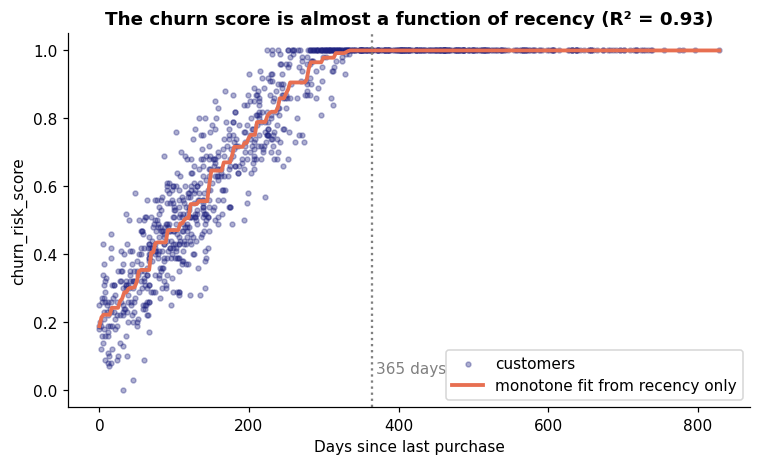

In [8]:
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.scatter(df["recency_days"], df["churn_risk_score"], s=10, alpha=.35, color="#1e2280", label="customers")
xs = np.linspace(0, df["recency_days"].max(), 300)
ax.plot(xs, iso.predict(xs), color="#e76f51", lw=2.5, label="monotone fit from recency only")
ax.axvline(365, ls=":", color="grey"); ax.text(370, 0.05, "365 days", color="grey")
ax.set_xlabel("Days since last purchase"); ax.set_ylabel("churn_risk_score")
ax.set_title(f"The churn score is almost a function of recency (R² = {r2_iso:.2f})"); ax.legend(loc="lower right")
save(fig, "02_churn_score_vs_recency.png")

**Conclusion.** The supplied `churn_risk_score` is close to a monotone transformation of recency, and every customer inactive for more than
365 days has a score of exactly 1.00. It is not an independent predictive model.

Consequences for this project:
- It is **removed from all clustering inputs**. Keeping it would count recency twice.
- "High churn risk" (score >= 0.70) is reported only as a descriptive fact about the supplied score, not as a model prediction.
- No segment is described as "high churn risk" on the basis of the score. Recency is reported directly instead.

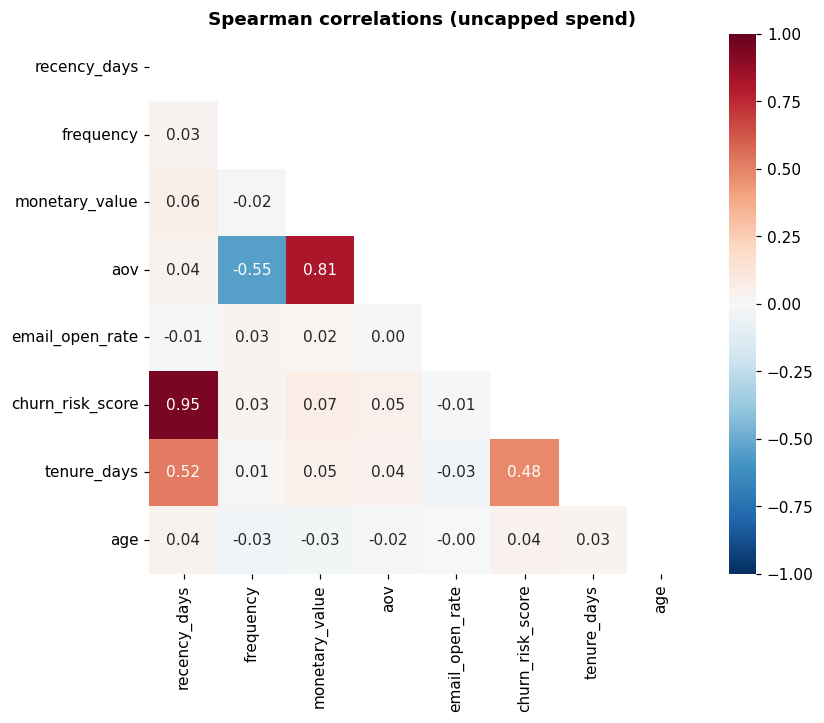

In [9]:
corr_cols = ["recency_days", "frequency", "monetary_value", "aov", "email_open_rate", "churn_risk_score", "tenure_days", "age"]
corr = df[corr_cols].corr(method="spearman")
fig, ax = plt.subplots(figsize=(8, 6.5))
sns.heatmap(corr, mask=np.triu(np.ones_like(corr, bool)), annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1, ax=ax)
ax.set_title("Spearman correlations (uncapped spend)")
save(fig, "03_correlation_matrix.png")

## 5. Deterministic RFM scores and why the original segments were unstable

The original notebook scored frequency with `pd.qcut(frequency.rank(method="first"), 5)`.
Frequency is a small integer (most customers have 2 to 6 orders), so hundreds of customers share each value.
`rank(method="first")` breaks those ties **by row position**, so two customers with the same number of orders can get different F scores.
Spend was scored the same way, but spend is continuous and almost never tied.

Below, the original rules are reproduced exactly (using the original preprocessing) and checked against the original export.
Then the row order is shuffled 20 times.

In [10]:
# Rebuild the ORIGINAL preprocessing exactly, only to reproduce and diagnose the original results.
legacy = raw.drop_duplicates().reset_index(drop=True).copy()
legacy["frequency"] = legacy["frequency"].fillna(legacy["frequency"].median())
legacy["monetary_value_capped"] = legacy["monetary_value"].clip(upper=legacy["monetary_value"].quantile(0.99))
legacy_seg = sg.legacy_rfm_segments(legacy, monetary_col="monetary_value_capped")

archived = pd.read_csv(ROOT / "archive" / "original_project" / "customer_segmentation_output.csv")
match = (legacy_seg.values == archived.set_index("customer_id").loc[legacy["customer_id"], "RFM_Segment"].values).mean()
print(f"Original segments reproduced: {match:.1%}")

legacy_changes = sg.order_sensitivity(legacy, lambda d: sg.legacy_rfm_segments(d, "monetary_value_capped"))
f_ties = pd.crosstab(legacy["frequency"], pd.qcut(legacy["frequency"].rank(method="first"), 5, labels=[1,2,3,4,5]))
print("Customers changing ORIGINAL segment when only row order changes (20 shuffles):",
      f"min {min(legacy_changes)}, median {int(np.median(legacy_changes))}, max {max(legacy_changes)}")
f_ties

Original segments reproduced: 100.0%
Customers changing ORIGINAL segment when only row order changes (20 shuffles): min 60, median 67, max 74


frequency,1,2,3,4,5
frequency,,,,,
0.0,17,0,0,0,0
1.0,74,0,0,0,0
2.0,109,43,0,0,0
3.0,0,157,25,0,0
4.0,0,0,175,29,0
5.0,0,0,0,152,0
6.0,0,0,0,19,101
7.0,0,0,0,0,55
8.0,0,0,0,0,26


In [11]:
scores = sg.rfm_scores(df)
new_seg_fn = lambda d: sg.assign_segments(d)[0]["segment"]
score_fn = lambda d: sg.rfm_scores(d)["RFM_code"]
new_changes = sg.order_sensitivity(df, new_seg_fn)
score_changes = sg.order_sensitivity(df, score_fn)
METRICS["order_sensitivity"] = {
    "original_segments_changed_min": min(legacy_changes), "original_segments_changed_median": int(np.median(legacy_changes)),
    "original_segments_changed_max": max(legacy_changes), "original_reproduction_rate": match,
    "revised_segments_changed_max": max(new_changes), "revised_rfm_codes_changed_max": max(score_changes),
}
print("Revised segments changed under 20 row shuffles: max", max(new_changes))
print("Revised RFM codes changed under 20 row shuffles: max", max(score_changes))
pd.crosstab(df["frequency"], scores["F_score"])

Revised segments changed under 20 row shuffles: max 0
Revised RFM codes changed under 20 row shuffles: max 0


F_score,1,2,3,4,5
frequency,,,,,
1,91,0,0,0,0
2,0,152,0,0,0
3,0,0,182,0,0
4,0,0,204,0,0
5,0,0,0,152,0
6,0,0,0,120,0
7,0,0,0,0,55
8,0,0,0,0,26
9,0,0,0,0,10


**Cause.** The instability came entirely from the `rank(method="first")` tie-break inside the frequency score. It was not caused by
K-Means, by distance ties, or by preprocessing. The fix is to score frequency with fixed order-count bins (1, 2, 3-4, 5-6, 7+), and to
compute recency and spend quintiles on the values themselves, so equal values always get equal scores.
After the fix, shuffling the rows changes no assignment.

The F bins are deliberately unequal in size (3-4 orders is the largest group). Equal-sized frequency quintiles are not achievable
without splitting customers who have identical behaviour.

## 6. Primary segmentation: recency band x value tier

Two questions drive almost every CRM action: *how recently did this customer buy?* (contact strategy) and *how much are they
worth?* (how much to invest). Recency and total spend are nearly independent in this data, so the primary segmentation crosses them
directly, using fixed, readable thresholds:

| Dimension | Rule |
|---|---|
| Recency band | Active 0-90 days · Cooling 91-180 · Lapsing 181-365 · Lapsed >365 |
| Value tier | High-Value = top 20% of customers by total uncapped spend · Standard = the rest |
| Newer-customer flag | Tenure <= 180 days (an attribute, not a segment) |

Order count is reported in each profile but is not a segmentation axis, because it is nearly uncorrelated with spend and
splitting on it as well would create many small cells.

In [12]:
seg_frame, hv_threshold = sg.assign_segments(df)
df = df.join(scores).join(seg_frame)
METRICS["high_value_threshold_usd"] = hv_threshold
print(f"High-Value threshold (80th percentile of total spend): ${hv_threshold:,.2f}")
seg_profile = sg.profile(df).reindex(sg.SEGMENT_ORDER)
seg_profile

High-Value threshold (80th percentile of total spend): $368.35


,customers,share_of_customers_pct,revenue,revenue_share_pct,median_recency_days,median_orders,mean_orders,median_spend,mean_spend,median_aov,median_tenure_days,pct_newer_customers,median_email_open_rate,median_churn_score
segment,,,,,,,,,,,,,,
Active High-Value,38,3.8,20223.98,7.76,54.0,3.0,3.58,471.97,532.21,188.92,351.0,18.42,0.30,0.35
Active Standard,191,19.1,32436.92,12.45,50.0,4.0,3.92,164.58,169.83,42.94,319.0,23.56,0.28,0.32
Cooling High-Value,41,4.1,22345.54,8.58,139.0,4.0,4.17,480.89,545.01,110.99,314.0,17.07,0.32,0.56
Cooling Standard,199,19.9,34682.04,13.31,128.0,4.0,3.98,160.04,174.28,42.72,350.0,14.07,0.26,0.54
Lapsing High-Value,66,6.6,37365.97,14.34,255.0,4.0,4.32,466.96,566.15,128.27,478.0,0.00,0.26,0.93
Lapsing Standard,217,21.7,39027.03,14.98,256.0,4.0,4.15,166.84,179.85,42.93,475.0,0.00,0.27,0.91
Lapsed High-Value,55,5.5,40471.88,15.54,500.0,3.0,3.51,516.28,735.85,204.83,686.0,0.00,0.25,1.00
Lapsed Standard,193,19.3,33930.64,13.03,478.0,4.0,4.02,162.88,175.81,40.24,658.0,0.00,0.27,1.00


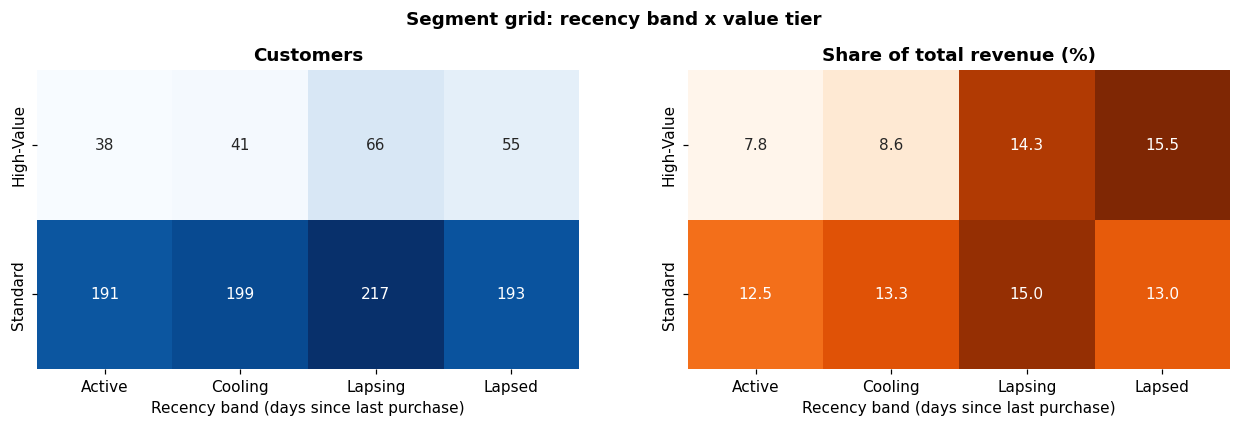

In [13]:
grid_n = pd.crosstab(df["value_tier"], df["recency_band"]).reindex(index=["High-Value", "Standard"], columns=["Active", "Cooling", "Lapsing", "Lapsed"])
grid_rev = df.pivot_table(index="value_tier", columns="recency_band", values="monetary_value", aggfunc="sum").reindex_like(grid_n) / df["monetary_value"].sum() * 100
fig, ax = plt.subplots(1, 2, figsize=(14, 3.6))
sns.heatmap(grid_n, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax[0]); ax[0].set_title("Customers")
sns.heatmap(grid_rev, annot=True, fmt=".1f", cmap="Oranges", cbar=False, ax=ax[1]); ax[1].set_title("Share of total revenue (%)")
for a in ax: a.set_xlabel("Recency band (days since last purchase)"); a.set_ylabel("")
fig.suptitle("Segment grid: recency band x value tier", fontweight="bold", y=1.03)
save(fig, "04_segment_grid.png")

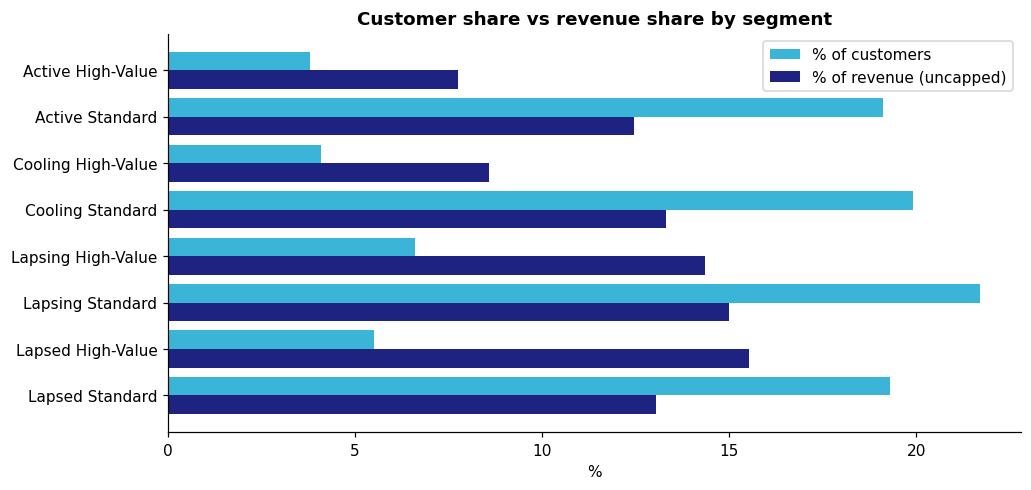

In [14]:
p = seg_profile[["share_of_customers_pct", "revenue_share_pct"]]
fig, ax = plt.subplots(figsize=(10, 4.8))
y = np.arange(len(p))
ax.barh(y - .2, p["share_of_customers_pct"], .4, label="% of customers", color="#3ab5d8")
ax.barh(y + .2, p["revenue_share_pct"], .4, label="% of revenue (uncapped)", color="#1e2280")
ax.set_yticks(y); ax.set_yticklabels(p.index); ax.invert_yaxis(); ax.set_xlabel("%"); ax.legend()
ax.set_title("Customer share vs revenue share by segment")
save(fig, "05_segment_customer_vs_revenue_share.png")

In [15]:
# How the original labels map onto the revised segments (original preprocessing, same customers)
mapping = pd.crosstab(pd.Series(legacy_seg.values, name="original_segment"), pd.Series(df["segment"].values, name="revised_segment"))
mapping = mapping.reindex(columns=sg.SEGMENT_ORDER)
mapping.to_csv(REPORT_TABLE_DIR / "original_vs_revised_segments.csv")
mapping

revised_segment,Active High-Value,Active Standard,Cooling High-Value,Cooling Standard,Lapsing High-Value,Lapsing Standard,Lapsed High-Value,Lapsed Standard
original_segment,,,,,,,,
At Risk,0,0,0,0,6,60,10,108
Champions,12,16,15,18,0,0,0,0
Hibernating,0,0,0,12,0,42,0,59
Loyal Customers,0,0,4,6,28,21,17,16
New Customers,22,79,9,63,0,0,0,0
Potential Loyalists,4,96,13,100,32,94,28,10


In [16]:
# Facts behind the relabelling of the original segments
orig = legacy.assign(original_segment=legacy_seg.values).merge(df[["customer_id", "tenure_days"]], on="customer_id")
orig_profile = orig.groupby("original_segment").agg(
    customers=("customer_id", "size"), median_recency_days=("recency_days", "median"),
    median_orders=("frequency", "median"), median_spend=("monetary_value", "median"),
    median_tenure_days=("tenure_days", "median"), median_churn_score=("churn_risk_score", "median"))
orig_profile["pct_recency_over_180"] = orig.groupby("original_segment")["recency_days"].apply(lambda s: (s > 180).mean() * 100)
orig_profile["pct_tenure_over_365"] = orig.groupby("original_segment")["tenure_days"].apply(lambda s: (s > 365).mean() * 100)
orig_profile.round(1).to_csv(REPORT_TABLE_DIR / "original_segment_profiles_recomputed.csv")
orig_profile.round(1)

,customers,median_recency_days,median_orders,median_spend,median_tenure_days,median_churn_score,pct_recency_over_180,pct_tenure_over_365
original_segment,,,,,,,,
At Risk,184,410.0,4.0,159.5,640.5,1.0,100.0,93.5
Champions,61,99.0,6.0,360.8,325.0,0.5,0.0,42.6
Hibernating,113,386.0,2.0,120.1,593.0,1.0,89.4,85.8
Loyal Customers,92,304.0,6.0,384.6,560.0,1.0,89.1,80.4
New Customers,173,80.0,2.0,205.9,334.0,0.4,0.0,42.8
Potential Loyalists,377,159.0,4.0,199.4,426.0,0.6,43.5,60.7


**Why the original labels were replaced**
- **"Loyal Customers"** were defined by high order count and spend with no recency condition. Most of them have not purchased for a long time.
  In the revised scheme they fall mainly into the *Lapsing* and *Lapsed* High-Value segments.
- **"New Customers"** had no tenure condition at all. Their median tenure is close to a year, and no customer in the data signed up recently.
- **"Potential Loyalists"** was the catch-all at the end of the rule chain and mixed very recent and long-lapsed customers.

The revised names describe only what is measured (time since last purchase and total spend). They make no claim about loyalty,
intent or future behaviour.

## 7. Clustering: does K-Means find real structure?

Three feature sets are compared:
- **Original:** recency, orders, capped spend, email open rate, churn score (as in the original notebook).
- **Without churn:** the same, with the churn score removed.
- **Revised:** recency, orders and `log1p(spend)`. Email open rate is excluded because it does not vary with purchasing behaviour (Section 8).

All features are standardised. For each k from 2 to 8 the table reports inertia, silhouette, a **null silhouette** (the same data with
each column shuffled independently, which keeps the distributions but removes any joint structure), Davies-Bouldin,
Calinski-Harabasz, bootstrap stability (ARI on 80% subsamples), row-shuffle stability, agreement with Ward hierarchical
clustering and the Gaussian-mixture BIC.

In [17]:
legacy_X = cl.scale(legacy, cl.ORIGINAL_FEATURES)
orig_km = cl.fit_kmeans(legacy_X, 3)
print("Original K-Means reproduced (ARI vs archived export):",
      round(adjusted_rand_score(archived.set_index("customer_id").loc[legacy["customer_id"], "Cluster"], orig_km.labels_), 3))

feature_sets = {
    "original (5 features, incl. churn)": (legacy, cl.ORIGINAL_FEATURES),
    "original without churn (4 features)": (legacy, [f for f in cl.ORIGINAL_FEATURES if f != "churn_risk_score"]),
    "revised (recency, orders, log spend)": (df, cl.REVISED_FEATURES),
}
selection = {}
for name, (frame, feats) in feature_sets.items():
    selection[name] = cl.model_selection(cl.scale(frame, feats))
selection_all = pd.concat(selection, names=["feature_set", "k"])
selection_all.round(3).to_csv(REPORT_TABLE_DIR / "kmeans_model_selection.csv")

# Gaussian-mixture BIC for k = 1 (a single blob) as the baseline for "is there more than one group at all?"
from sklearn.mixture import GaussianMixture
bic_k1 = GaussianMixture(1, random_state=RANDOM_STATE).fit(cl.scale(df, cl.REVISED_FEATURES)).bic(cl.scale(df, cl.REVISED_FEATURES))
print(f"Revised features: GMM BIC k=1 = {bic_k1:,.1f}; best k>1 = {selection['revised (recency, orders, log spend)']['gmm_bic'].min():,.1f}")
selection_all.round(3)

Original K-Means reproduced (ARI vs archived export): 1.0
Revised features: GMM BIC k=1 = 8,570.4; best k>1 = 8,296.7


inertia  silhouette  null_silhouette  davies_bouldin  calinski_harabasz  bootstrap_ari_mean  bootstrap_ari_min  \
feature_set                          k                                                                                                                    
original (5 features, incl. churn)   2  3557.365       0.277            0.176           1.453            404.724               0.985              0.951   
                                     3  3107.721       0.280            0.177           1.341            303.535               0.804              0.500   
                                     4  2704.654       0.236            0.189           1.398            281.757               0.797              0.408   
                                     5  2376.371       0.218            0.188           1.419            274.632               0.847              0.363   
                                     6  2133.160       0.218            0.185           1.346            267.175               0.837              0.673   
                                     7  1954.818       0.209            0.181           1.302            257.813               0.823              0.467   
                                     8  1839.492       0.195            0.179           1.306            243.485               0.635              0.480   
original without churn (4 features)  2  3250.781       0.226            0.216           1.861            230.020               0.906              0.015   
                                     3  2729.509       0.198            0.214           1.568            232.034               0.787              0.291   
                                     4  2298.840       0.216            0.227           1.363            245.706               0.742              0.313   
                                     5  1923.982       0.226            0.228           1.183            268.407               0.897              0.718   
                                     6  1759.006       0.220            0.219           1.248            253.274               0.699              0.453   
                                     7  1607.242       0.212            0.217           1.297            246.386               0.869              0.525   
                                     8  1490.445       0.215            0.212           1.258            238.613               0.864              0.730   
revised (recency, orders, log spend) 2  2257.917       0.264            0.270           1.505            328.001               0.974              0.873   
                                     3  1730.386       0.269            0.263           1.252            365.758               0.981              0.835   
                                     4  1395.276       0.270            0.278           1.068            381.837               0.911              0.847   
                                     5  1223.784       0.262            0.259           1.169            361.046               0.898              0.738   
                                     6  1100.350       0.257            0.247           1.238            343.209               0.759              0.478   
                                     7  1001.334       0.251            0.244           1.171            330.338               0.679              0.451   
                                     8   918.386       0.252            0.243           1.160            321.227               0.729              0.421   

                                        row_shuffle_ari_min  ward_agreement_ari    gmm_bic  smallest_cluster  largest_cluster  
feature_set                          k                                                                                         
original (5 features, incl. churn)   2                1.000               0.743   7784.754               481              519  
                                     3                0.924               0.666   7702.427 

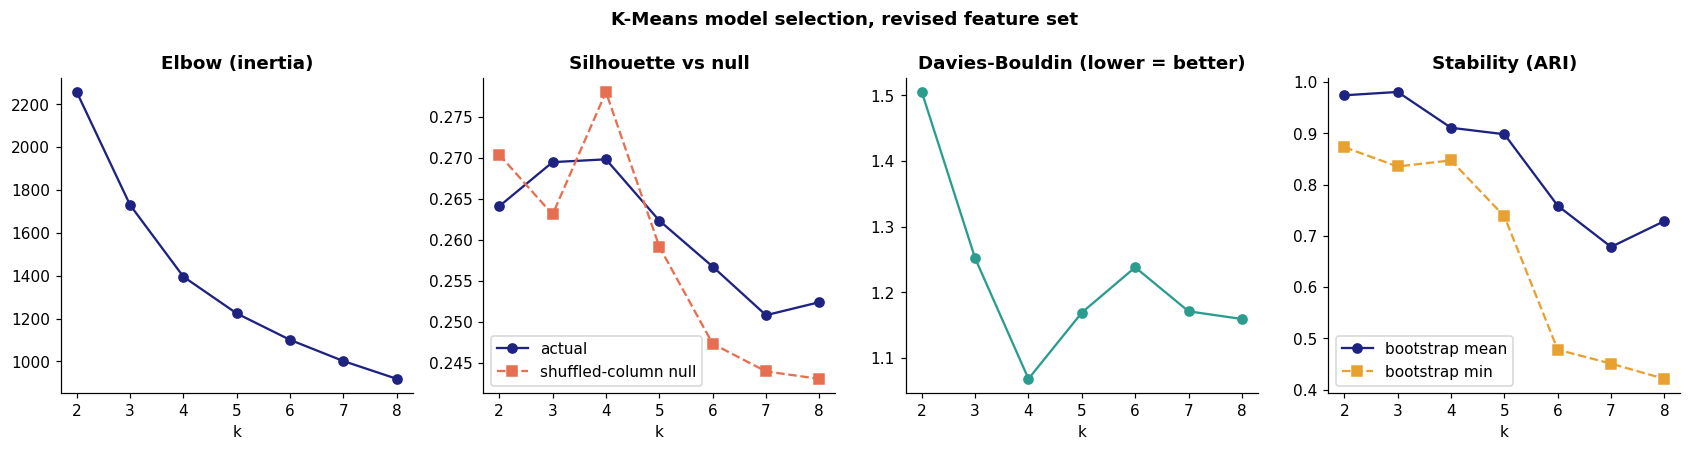

In [18]:
rev = selection["revised (recency, orders, log spend)"]
fig, ax = plt.subplots(1, 4, figsize=(19, 3.8))
ax[0].plot(rev.index, rev["inertia"], "o-", color="#1e2280"); ax[0].set_title("Elbow (inertia)")
ax[1].plot(rev.index, rev["silhouette"], "o-", label="actual", color="#1e2280")
ax[1].plot(rev.index, rev["null_silhouette"], "s--", label="shuffled-column null", color="#e76f51"); ax[1].legend(); ax[1].set_title("Silhouette vs null")
ax[2].plot(rev.index, rev["davies_bouldin"], "o-", color="#2a9d8f"); ax[2].set_title("Davies-Bouldin (lower = better)")
ax[3].plot(rev.index, rev["bootstrap_ari_mean"], "o-", label="bootstrap mean", color="#1e2280")
ax[3].plot(rev.index, rev["bootstrap_ari_min"], "s--", label="bootstrap min", color="#e8a030"); ax[3].legend(); ax[3].set_title("Stability (ARI)")
for a in ax: a.set_xlabel("k")
fig.suptitle("K-Means model selection, revised feature set", fontweight="bold", y=1.04)
save(fig, "06_kmeans_model_selection.png")

**Reading the model-selection table**
- With the revised features, the silhouette is essentially the same as the shuffled-column null for every k. A partition of data
  with no joint structure scores just as well, so **there is no evidence of natural, well-separated customer clusters**.
  K-Means is cutting a continuous cloud.
- The elbow curve has no clear bend.
- The metrics disagree about k. Silhouette is flat, Davies-Bouldin and Calinski-Harabasz favour k = 4, and bootstrap stability,
  row-shuffle stability and the Gaussian-mixture BIC favour k = 3. No k is justified by agreement across metrics.
- The Gaussian mixture prefers several components over one. That is expected even without real groups, because recency is roughly flat,
  orders are discrete and spend is skewed, so no single Gaussian fits well. Taken together with the null silhouette, it is not evidence of separated segments.
- In the original 5-feature model the silhouette sits clearly above its null only because the churn score and recency move together.
  With the churn score removed, the original features score **no better than** their null, and stability collapses for some k.
  The original "structure" was largely the duplicated recency signal.
- The original k = 3 solution is also mildly sensitive to row order (row-shuffle ARI below 1), because K-Means initialisation depends on row order.
  The revised k = 3 solution is close to order-invariant.

In [19]:
K_EXPLORATORY = 3
Xr = cl.scale(df, cl.REVISED_FEATURES)
km = cl.fit_kmeans(Xr, K_EXPLORATORY)
df["exploratory_cluster"] = cl.relabel_by_centroid(df, km.labels_, key="recency_days")

tree, tree_acc = cl.rule_reproduction(df, ["recency_days", "frequency", "monetary_value"], df["exploratory_cluster"], depth=2)
from sklearn.tree import export_text
print(export_text(tree, feature_names=["recency_days", "frequency", "monetary_value"]))
eta = cl.eta_squared(df, df["exploratory_cluster"].values, ["recency_days", "frequency", "log_monetary", "email_open_rate"])
orig_tree, orig_tree_acc = cl.rule_reproduction(legacy, ["recency_days", "monetary_value_capped"], orig_km.labels_, depth=2)
METRICS["clustering"] = {
    "k_exploratory": K_EXPLORATORY,
    "revised_silhouette": float(rev.loc[K_EXPLORATORY, "silhouette"]),
    "revised_null_silhouette": float(rev.loc[K_EXPLORATORY, "null_silhouette"]),
    "revised_bootstrap_ari_mean": float(rev.loc[K_EXPLORATORY, "bootstrap_ari_mean"]),
    "revised_tree_depth2_accuracy": tree_acc,
    "original_tree_depth2_accuracy_recency_spend": orig_tree_acc,
    "ari_exploratory_cluster_vs_rule_segments": adjusted_rand_score(df["exploratory_cluster"], df["segment"]),
    "ari_exploratory_cluster_vs_recency_band": adjusted_rand_score(df["exploratory_cluster"], df["recency_band"]),
    "ari_revised_vs_original_clusters": adjusted_rand_score(df["exploratory_cluster"], orig_km.labels_),
    "original_selection": selection["original (5 features, incl. churn)"].loc[[2, 3, 4], ["silhouette", "null_silhouette", "bootstrap_ari_mean"]].round(3).to_dict(),
}
print(f"Depth-2 tree reproduces {tree_acc:.1%} of revised clusters; {orig_tree_acc:.1%} of original clusters from recency + capped spend alone")
print("Share of each feature's variance explained by cluster (eta squared):"); print(eta.round(3))
cluster_profile = sg.profile(df, by="exploratory_cluster")
cluster_profile

|--- recency_days <= 297.50
|   |--- frequency <= 4.50
|   |   |--- class: 0
|   |--- frequency >  4.50
|   |   |--- class: 1
|--- recency_days >  297.50
|   |--- recency_days <= 371.50
|   |   |--- class: 2
|   |--- recency_days >  371.50
|   |   |--- class: 2

Depth-2 tree reproduces 95.1% of revised clusters; 96.5% of original clusters from recency + capped spend alone
Share of each feature's variance explained by cluster (eta squared):
recency_days       0.691
frequency          0.563
log_monetary       0.015
email_open_rate    0.001
dtype: float64


,customers,share_of_customers_pct,revenue,revenue_share_pct,median_recency_days,median_orders,mean_orders,median_spend,mean_spend,median_aov,median_tenure_days,pct_newer_customers,median_email_open_rate,median_churn_score
exploratory_cluster,,,,,,,,,,,,,,
0,418,41.8,98207.37,37.70,123.0,3.0,2.70,196.40,234.95,73.22,391.0,12.44,0.26,0.54
1,288,28.8,69467.69,26.67,140.0,6.0,6.17,194.84,241.21,31.09,403.0,12.15,0.28,0.59
2,294,29.4,92808.94,35.63,461.5,4.0,3.73,228.08,315.68,61.80,656.5,0.00,0.26,1.00


In [20]:
pd.crosstab(df["exploratory_cluster"], df["segment"]).reindex(columns=sg.SEGMENT_ORDER)

segment,Active High-Value,Active Standard,Cooling High-Value,Cooling Standard,Lapsing High-Value,Lapsing Standard,Lapsed High-Value,Lapsed Standard
exploratory_cluster,,,,,,,,
0,26,119,23,123,23,104,0,0
1,12,72,18,76,21,79,0,10
2,0,0,0,0,22,34,55,183


In [21]:
print("Original cluster sizes:", sorted(np.bincount(orig_km.labels_)))
print("Revised exploratory cluster sizes:", np.bincount(df["exploratory_cluster"]).tolist())
pd.crosstab(pd.Series(orig_km.labels_, name="original_cluster"), pd.Series(df["exploratory_cluster"].values, name="revised_cluster"))

Original cluster sizes: [67, 428, 505]
Revised exploratory cluster sizes: [418, 288, 294]


revised_cluster,0,1,2
original_cluster,,,
0,18,16,33
1,82,85,261
2,318,187,0


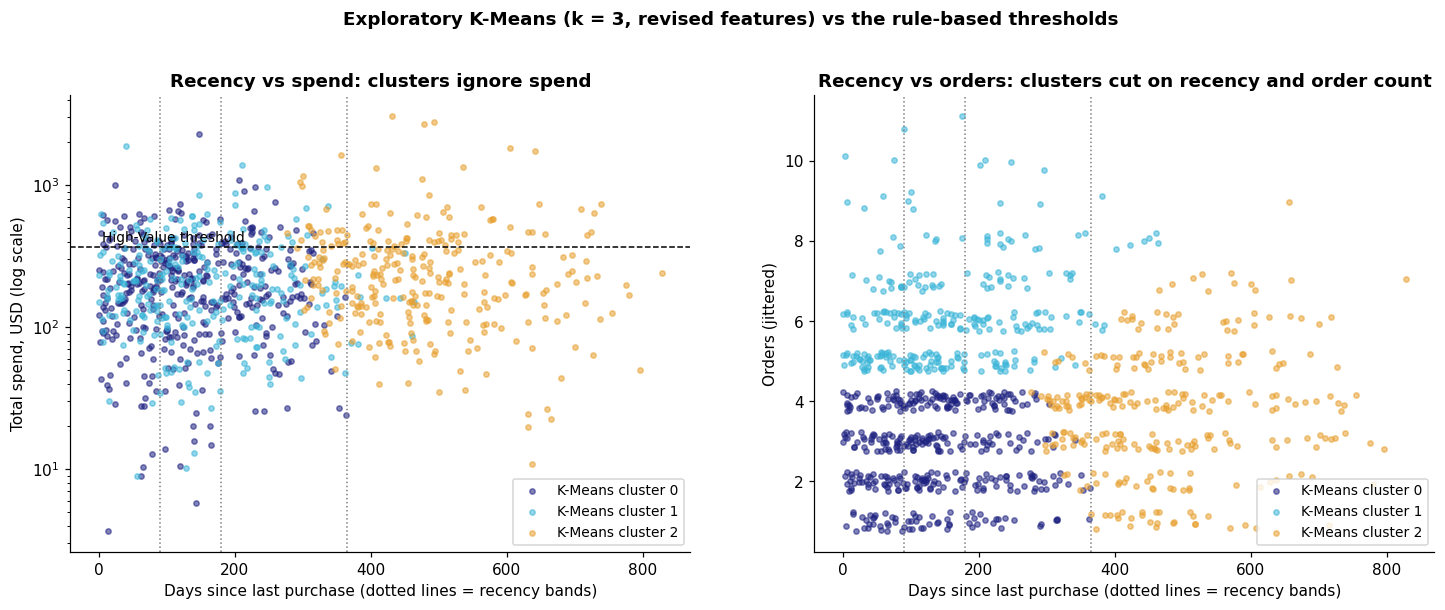

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))
colors = ["#1e2280", "#3ab5d8", "#e8a030", "#2a9d8f", "#e76f51"]
jitter = np.random.default_rng(0).uniform(-0.25, 0.25, len(df))
for c in sorted(df["exploratory_cluster"].unique()):
    m = (df["exploratory_cluster"] == c).values
    axes[0].scatter(df.loc[m, "recency_days"], df.loc[m, "monetary_value"], s=12, alpha=.55, color=colors[c], label=f"K-Means cluster {c}")
    axes[1].scatter(df.loc[m, "recency_days"], df.loc[m, "frequency"] + jitter[m], s=12, alpha=.55, color=colors[c], label=f"K-Means cluster {c}")
axes[0].set_yscale("log")
axes[0].axhline(hv_threshold, color="black", ls="--", lw=1); axes[0].text(5, hv_threshold * 1.08, "High-Value threshold", fontsize=9)
axes[0].set_ylabel("Total spend, USD (log scale)"); axes[0].set_title("Recency vs spend: clusters ignore spend")
axes[1].set_ylabel("Orders (jittered)"); axes[1].set_title("Recency vs orders: clusters cut on recency and order count")
for a in axes:
    for x in [90, 180, 365]: a.axvline(x, color="grey", ls=":", lw=1)
    a.set_xlabel("Days since last purchase (dotted lines = recency bands)"); a.legend(loc="lower right", fontsize=9)
fig.suptitle("Exploratory K-Means (k = 3, revised features) vs the rule-based thresholds", fontweight="bold", y=1.02)
save(fig, "07_kmeans_vs_rule_thresholds.png")

**Does K-Means add value here?** Very little:
- A depth-2 decision tree on raw variables reproduces about 95% of both the original and the revised cluster labels.
  The clusters are simple threshold rules in disguise.
- *Which* thresholds depends on the feature set. The original model split on recency and capped spend. The revised model splits
  on recency (around 300 days) and order count (around 4-5 orders), and spend explains almost none of its cluster differences.
  When the chosen features decide what the "segments" are, the clusters are not natural groups in the data.
- The revised clusters can be read as: recently active with fewer orders, recently active with more orders, and lapsed.
  They agree only weakly with the recency x value grid (low ARI), because they cut on order count rather than spend.
- The silhouette is no better than the shuffled null, and the choice of k is not supported by agreement across metrics.

**Decision.** The rule-based recency x value grid is the primary segmentation, because it is transparent, deterministic and easy to refresh.
The K-Means partition is kept only as an exploratory label, exported for reference and not used for any recommendation.
k = 3 was chosen for that label because it was the most stable under resampling among the candidates, not because the data shows three groups.

## 8. Revalidating customer insights

**Which tests.** Kruskal-Wallis (no normality assumption) for numeric outcomes across groups, with epsilon-squared effect size.
Chi-square tests of independence for categorical pairs, with Cramér's V; all expected cell counts are reported and checked.
All tests are treated as one family and Holm-corrected.

Segments are **not** tested on recency or spend, because they are defined by those variables, so such a test would be circular.

In [23]:
specs = [
    ("Spend by acquisition channel", "kruskal", "monetary_value", "acquisition_channel"),
    ("Orders by acquisition channel", "kruskal", "frequency", "acquisition_channel"),
    ("AOV by acquisition channel", "kruskal", "aov", "acquisition_channel"),
    ("Recency by acquisition channel", "kruskal", "recency_days", "acquisition_channel"),
    ("Churn score by acquisition channel", "kruskal", "churn_risk_score", "acquisition_channel"),
    ("Spend by preferred category", "kruskal", "monetary_value", "preferred_category"),
    ("Orders by preferred category", "kruskal", "frequency", "preferred_category"),
    ("Spend by country", "kruskal", "monetary_value", "country"),
    ("Email open rate by segment", "kruskal", "email_open_rate", "segment"),
    ("Age by segment", "kruskal", "age", "segment"),
    ("Segment x acquisition channel", "chi2", "segment", "acquisition_channel"),
    ("Segment x preferred category", "chi2", "segment", "preferred_category"),
    ("Segment x country", "chi2", "segment", "country"),
    ("Segment x gender", "chi2", "segment", "gender"),
    ("Value tier x acquisition channel", "chi2", "value_tier", "acquisition_channel"),
    ("Value tier x preferred category", "chi2", "value_tier", "preferred_category"),
]
tests = st.run_family(df, specs)
tests.round(4).to_csv(REPORT_TABLE_DIR / "insight_tests.csv")
METRICS["insight_tests_significant_after_holm"] = tests.index[tests["significant_at_0.05_after_holm"]].tolist()
tests[["test", "n", "statistic", "p_value", "p_holm", "effect_measure", "effect_size", "min_expected", "significant_at_0.05_after_holm"]].round(4)

,test,n,statistic,p_value,p_holm,effect_measure,effect_size,min_expected,significant_at_0.05_after_holm
comparison,,,,,,,,,
Spend by acquisition channel,Kruskal-Wallis,1000,1.2064,0.8770,1.0,epsilon_squared,0.0012,NaN,False
Orders by acquisition channel,Kruskal-Wallis,1000,0.7205,0.9488,1.0,epsilon_squared,0.0007,NaN,False
AOV by acquisition channel,Kruskal-Wallis,957,1.5919,0.8102,1.0,epsilon_squared,0.0017,NaN,False
Recency by acquisition channel,Kruskal-Wallis,1000,4.7332,0.3158,1.0,epsilon_squared,0.0047,NaN,False
Churn score by acquisition channel,Kruskal-Wallis,1000,5.3032,0.2576,1.0,epsilon_squared,0.0053,NaN,False
Spend by preferred category,Kruskal-Wallis,1000,4.3785,0.3572,1.0,epsilon_squared,0.0044,NaN,False
Orders by preferred category,Kruskal-Wallis,1000,2.5988,0.6270,1.0,epsilon_squared,0.0026,NaN,False
Spend by country,Kruskal-Wallis,1000,7.2373,0.1239,1.0,epsilon_squared,0.0072,NaN,False
Email open rate by segment,Kruskal-Wallis,1000,5.2382,0.6309,1.0,epsilon_squared,0.0052,NaN,False


In [24]:
corrs = pd.DataFrame([
    {"pair": a + " vs " + b, "spearman_rho": stats.spearmanr(df[a], df[b], nan_policy="omit").correlation,
     "p_value": stats.spearmanr(df[a], df[b], nan_policy="omit").pvalue}
    for a, b in [("email_open_rate", "monetary_value"), ("email_open_rate", "recency_days"), ("email_open_rate", "frequency"),
                 ("tenure_days", "monetary_value"), ("age", "monetary_value")]
]).set_index("pair")
corrs["p_holm"] = st.holm(corrs["p_value"])
corrs.round(4)

,spearman_rho,p_value,p_holm
pair,,,
email_open_rate vs monetary_value,0.0208,0.5105,1.0000
email_open_rate vs recency_days,-0.0109,0.7299,1.0000
email_open_rate vs frequency,0.0262,0.4086,1.0000
tenure_days vs monetary_value,0.0522,0.0993,0.4964
age vs monetary_value,-0.0310,0.3276,1.0000


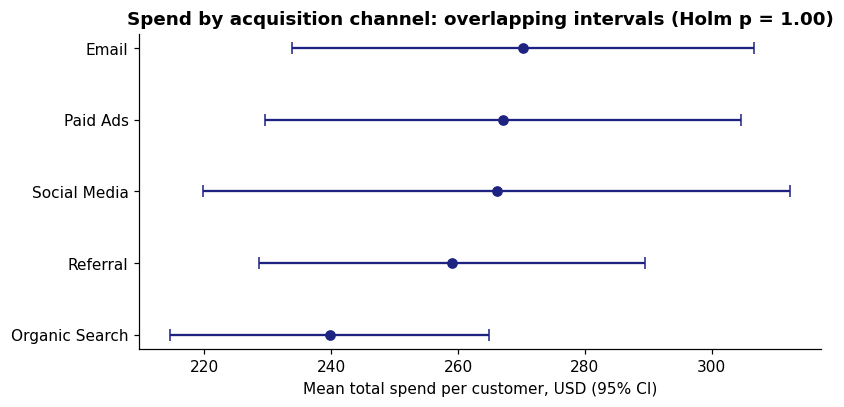

,customers,mean_spend,sd,median_spend,ci95_low,ci95_high
acquisition_channel,,,,,,
Organic Search,200,239.76,181.36,185.84,214.63,264.90
Referral,196,259.09,217.47,208.90,228.65,289.54
Social Media,201,266.08,334.72,197.80,219.81,312.36
Paid Ads,200,267.10,271.06,209.56,229.54,304.67
Email,203,270.17,264.65,210.99,233.77,306.58


In [25]:
channel = df.groupby("acquisition_channel").agg(customers=("customer_id", "size"), mean_spend=("monetary_value", "mean"),
                                                 sd=("monetary_value", "std"), median_spend=("monetary_value", "median"))
channel["ci95_low"] = channel["mean_spend"] - 1.96 * channel["sd"] / np.sqrt(channel["customers"])
channel["ci95_high"] = channel["mean_spend"] + 1.96 * channel["sd"] / np.sqrt(channel["customers"])
channel = channel.sort_values("mean_spend")
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.errorbar(channel["mean_spend"], channel.index, xerr=[channel["mean_spend"] - channel["ci95_low"], channel["ci95_high"] - channel["mean_spend"]],
            fmt="o", color="#1e2280", capsize=4)
ax.set_xlabel("Mean total spend per customer, USD (95% CI)")
ax.set_title(f"Spend by acquisition channel: overlapping intervals (Holm p = {tests.loc['Spend by acquisition channel', 'p_holm']:.2f})")
save(fig, "08_spend_by_channel_with_ci.png")
channel.round(2)

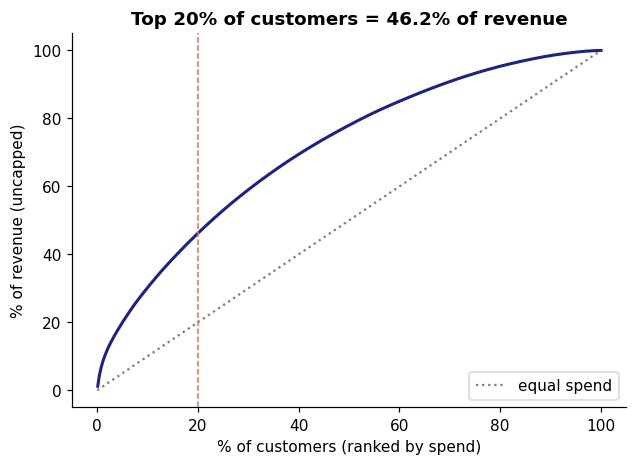

top_10pct_revenue_share    0.302
top_20pct_revenue_share    0.462
top_50pct_revenue_share    0.780
dtype: float64

In [26]:
s = df["monetary_value"].sort_values(ascending=False).reset_index(drop=True)
cum = s.cumsum() / s.sum()
METRICS["concentration"] = {"top_10pct_revenue_share": cum.iloc[int(.1 * len(s)) - 1], "top_20pct_revenue_share": cum.iloc[int(.2 * len(s)) - 1],
                            "top_50pct_revenue_share": cum.iloc[int(.5 * len(s)) - 1]}
fig, ax = plt.subplots(figsize=(6.5, 4.5))
ax.plot(np.arange(1, len(s) + 1) / len(s) * 100, cum * 100, color="#1e2280", lw=2)
ax.plot([0, 100], [0, 100], ls=":", color="grey", label="equal spend")
ax.axvline(20, ls="--", color="#e76f51", lw=1)
ax.set_xlabel("% of customers (ranked by spend)"); ax.set_ylabel("% of revenue (uncapped)")
ax.set_title(f"Top 20% of customers = {METRICS['concentration']['top_20pct_revenue_share']:.1%} of revenue"); ax.legend()
save(fig, "09_revenue_concentration.png")
pd.Series(METRICS["concentration"]).round(3)

**What survives testing**
- Read the significance column above. Comparisons that are not significant after Holm correction are treated as **no detectable difference**.
  That covers acquisition channel, preferred category, country and gender in relation to spend, orders and segment membership,
  and email engagement across segments.
- A difference that is statistically significant but has a tiny effect size is not treated as commercially meaningful.
- Revenue is moderately concentrated: the top fifth of customers by spend account for well under half of revenue.

**Removed claims.** Channel rankings by "LTV", channel budget reallocation, category-based cross-sell between segments, and
"Loyal Customers outspend Champions" are all removed, because the data does not support them.

## 9. Reconciliation of the original project's figures

In [27]:
legacy_out = archived.set_index("customer_id")
champ = legacy_out["RFM_Segment"] == "Champions"; loyal = legacy_out["RFM_Segment"] == "Loyal Customers"
mwu = stats.mannwhitneyu(legacy_out.loc[loyal, "monetary_value"], legacy_out.loc[champ, "monetary_value"])
recon = pd.DataFrame([
    ("Average order value", "$253 (executive summary)", f"${behaviour['aov_mean_of_customer_aov']:.2f} mean per customer; ${behaviour['aov_order_weighted']:.2f} order-weighted",
     "Corrected: $253 was average total spend per customer"),
    ("Average total spend per customer", "$253 (capped spend)", f"${behaviour['mean_spend_per_customer']:.2f} uncapped", "Corrected: revenue now uncapped"),
    ("Total revenue", "~$253,046", f"${behaviour['total_revenue_uncapped']:,.2f} uncapped", "Corrected"),
    ("Customers with churn score >= 0.70", "~640 (64%) in executive summary; 539 (53.9%) in notebook",
     f"{METRICS['churn']['high_churn_count']} ({METRICS['churn']['high_churn_share']:.1%})", "Executive summary figure was wrong"),
    ("Median churn score", "0.71 (notebook conclusion)", f"{METRICS['churn']['median_churn_score']:.3f} (mean {METRICS['churn']['mean_churn_score']:.3f})", "Corrected"),
    ("Spend cap", "$799 (executive summary) / $1,315.02 (notebook)", "No cap; log transform for modelling", "Method changed"),
    ("Loyal Customers outspend Champions", "Yes, the 'most counterintuitive finding'", f"Mann-Whitney p = {mwu.pvalue:.2f}", "Removed: no detectable difference"),
    ("Row-order stability of segments", "Not assessed",
     f"{METRICS['order_sensitivity']['original_segments_changed_min']}-{METRICS['order_sensitivity']['original_segments_changed_max']} customers moved (original); "
     f"{METRICS['order_sensitivity']['revised_segments_changed_max']} (revised)", "Fixed"),
    ("Number of segments", "'five' in notebook text, six in code", f"{df['segment'].nunique()} rule-based segments", "Redefined"),
], columns=["metric", "original_claim", "verified_value", "status"]).set_index("metric")
recon.to_csv(REPORT_TABLE_DIR / "figure_reconciliation.csv")
recon

,original_claim,verified_value,status
metric,,,
Average order value,$253 (executive summary),$85.22 mean per customer; $64.50 order-weighted,Corrected: $253 was average total spend per cu...
Average total spend per customer,$253 (capped spend),$260.48 uncapped,Corrected: revenue now uncapped
Total revenue,"~$253,046","$260,484.00 uncapped",Corrected
Customers with churn score >= 0.70,~640 (64%) in executive summary; 539 (53.9%) i...,539 (53.9%),Executive summary figure was wrong
Median churn score,0.71 (notebook conclusion),0.745 (mean 0.706),Corrected
Spend cap,"$799 (executive summary) / $1,315.02 (notebook)",No cap; log transform for modelling,Method changed
Loyal Customers outspend Champions,"Yes, the 'most counterintuitive finding'",Mann-Whitney p = 0.53,Removed: no detectable difference
Row-order stability of segments,Not assessed,60-74 customers moved (original); 0 (revised),Fixed
Number of segments,"'five' in notebook text, six in code",8 rule-based segments,Redefined


## 10. Exports

In [28]:
clean_cols = ["customer_id", "gender", "age", "age_imputed", "age_under_18", "country", "signup_date", "last_purchase_date",
              "tenure_days", "recency_days", "frequency", "frequency_flag", "monetary_value", "aov", "preferred_category",
              "acquisition_channel", "email_open_rate", "churn_risk_score"]
df[clean_cols].to_csv(CLEAN_PATH, index=False, date_format="%Y-%m-%d")

export_cols = clean_cols + ["R_score", "F_score", "M_score", "RFM_code", "recency_band", "value_tier", "segment",
                            "newer_customer", "exploratory_cluster"]
df[export_cols].to_csv(PROCESSED_DIR / "customer_segments.csv", index=False, date_format="%Y-%m-%d")
seg_profile.to_csv(PROCESSED_DIR / "segment_profiles.csv")
cluster_profile.to_csv(PROCESSED_DIR / "exploratory_cluster_profiles.csv")
cleaning_log.to_csv(REPORT_TABLE_DIR / "cleaning_log.csv", index=False)

METRICS["segment_profiles"] = seg_profile.reset_index().to_dict(orient="records")
METRICS["environment"] = {"pandas": pd.__version__, "numpy": np.__version__, "scikit-learn": sklearn.__version__, "scipy": scipy.__version__}
def _clean(o):
    if isinstance(o, dict): return {str(k): _clean(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)): return [_clean(v) for v in o]
    if isinstance(o, (np.integer,)): return int(o)
    if isinstance(o, (np.floating, float)): return round(float(o), 4)
    if isinstance(o, (np.bool_,)): return bool(o)
    return o
(ROOT / "reports" / "metrics.json").write_text(json.dumps(_clean(METRICS), indent=2))
for p in [CLEAN_PATH, PROCESSED_DIR / "customer_segments.csv", PROCESSED_DIR / "segment_profiles.csv", ROOT / "reports" / "metrics.json"]:
    print("wrote", p.relative_to(ROOT))

wrote data\cleaned\customer_segmentation_cleaned.csv
wrote data\processed\customer_segments.csv
wrote data\processed\segment_profiles.csv
wrote reports\metrics.json


## 11. Limitations

- **Synthetic data.** Relationships were generated, not observed. The churn score, channels and categories appear to be generated
  largely independently of purchasing behaviour, which is why they show no detectable effects.
- **No transaction history.** Only customer-level totals exist, so there is no purchase timing, basket content, returns or margin.
  AOV is a ratio of totals, and cross-sell or category-journey analysis is not possible.
- **No costs or campaign outcomes.** No ROI, budget reallocation or revenue-uplift figure can be calculated. The segment actions in the
  README are hypotheses to test, not predicted results.
- **No genuinely new customers.** The newest signup is months before the analysis date.
- **A single snapshot.** Segment migration over time cannot be measured.
- **Thresholds are judgement calls.** The 90/180/365-day bands and the top-20% value cut-off are conventional, readable choices.
  Different cut-offs change segment sizes but not the conclusion that recency and spend are the only informative axes.
- **Data fixes.** The frequency corrections (zero-to-one and median imputation) affect segment scores for a small number of customers, all of them flagged.